<a href="https://colab.research.google.com/github/Digitalbuilder2026/Intro-to-Computer-Vision/blob/main/Copy_of_CV_Adding_Vectors.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
! git clone https://github.com/fenago/cv2

fatal: destination path 'cv2' already exists and is not an empty directory.


In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
%matplotlib inline

(480, 600, 3)


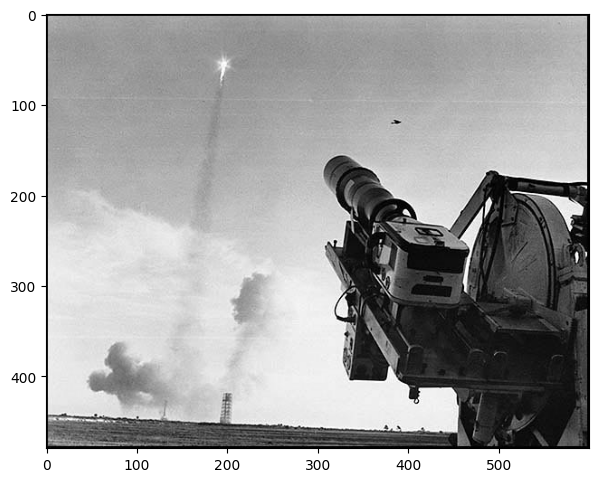

In [ ]:
# Read the image.
image = cv2.imread('/content/cv2/Mod1/Apollo-8-Launch.jpg', cv2.IMREAD_COLOR)

# Display the original image.
plt.figure(figsize = [7, 7])
plt.imshow(image);
print(image.shape)

In [ ]:
yellow  = (0, 255, 255)
red     = (0, 0, 255)
magenta = (255, 0, 255)
green   = (0, 255, 0)

In [ ]:
# Make a copy of the original image.
image_line = image.copy()

In [ ]:
# Draw a yellow line (using: cv2.LINE_8)
# image_line = cv2.line(image_line, (0, 445), (450, 465), yellow, thickness=3, lineType=cv2.LINE_8)

image_line = cv2.line(image_line, (0, 445), (450, 465), (0, 255, 0), thickness=6, lineType=cv2.LINE_8)

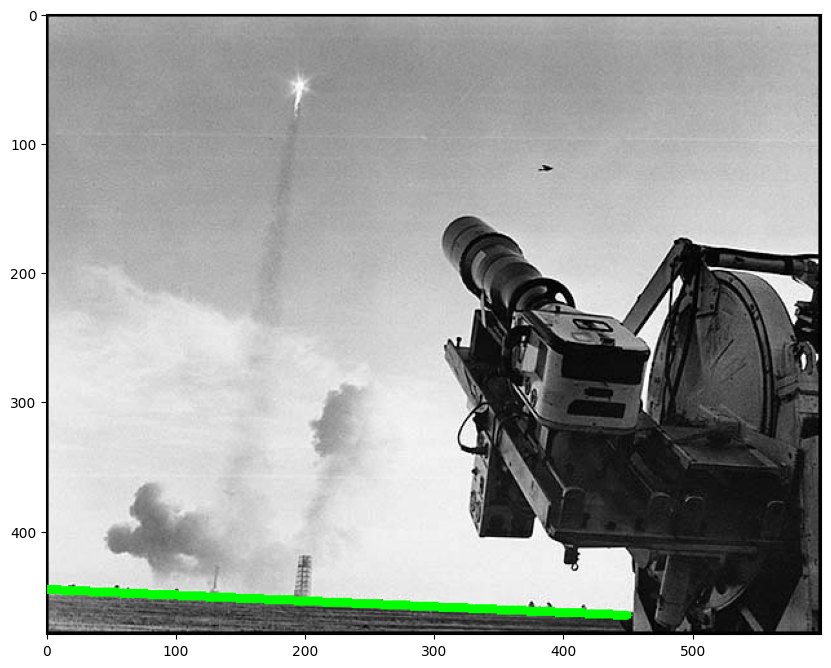

In [ ]:
# Display the annotated image.
plt.figure(figsize = [10, 10])
plt.imshow(image_line[:, :, ::-1]);

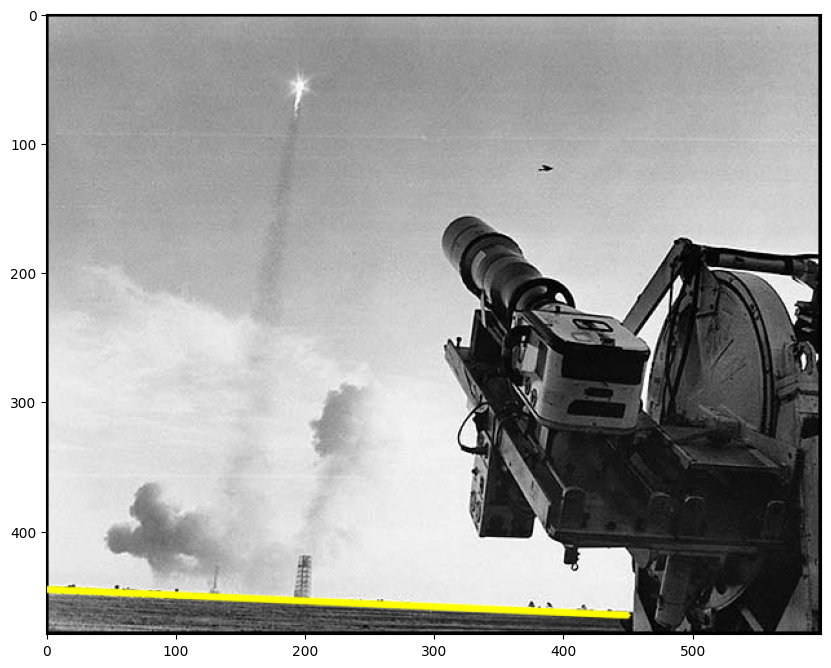

In [ ]:
# Make a copy of the original image.
image_line_aa = image.copy()

# Draw a yellow line (using: cv2.LINE_AA)
image_line_aa = cv2.line(image_line_aa, (0, 445), (450, 465), yellow, thickness=3, lineType=cv2.LINE_AA)

# Display the annotated image.
plt.figure(figsize = [10, 10])
plt.imshow(image_line_aa[:, :, ::-1]);

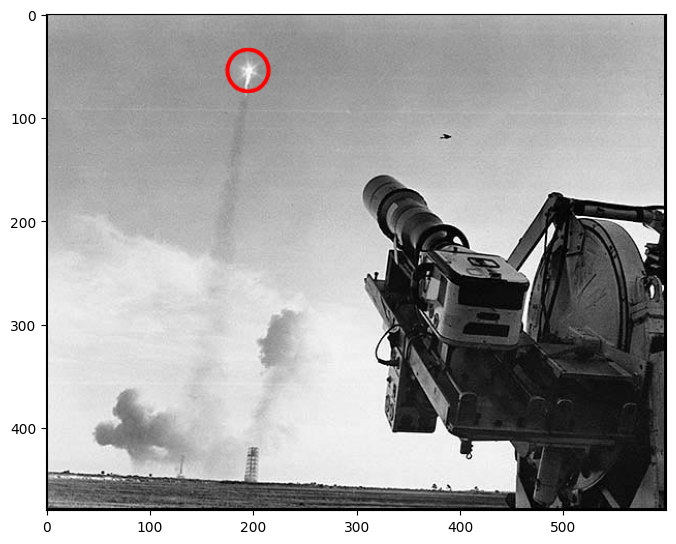

In [ ]:
# Make a copy of the original image.
image_circle = image.copy()

# Draw a red circle.
image_circle = cv2.circle(image_circle, (195, 55), 20, red, thickness = 2, lineType = cv2.LINE_AA)

# Display the annotated image.
plt.figure(figsize = [8, 8])
plt.imshow(image_circle[:, :, ::-1]);

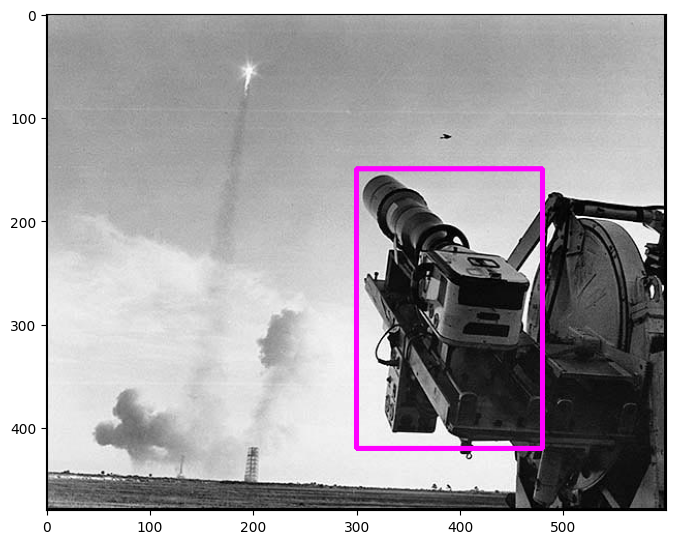

In [ ]:
# Make a copy of the original image.
image_rectangle = image.copy()

# Draw a magenta rectangle.
image_rectangle = cv2.rectangle(image_rectangle, (300, 150), (480, 420), magenta, thickness = 3, lineType = cv2.LINE_8)

# Display the annotated image.
plt.figure(figsize = [8, 8])
plt.imshow(image_rectangle[:, :, ::-1]);

Original Image:


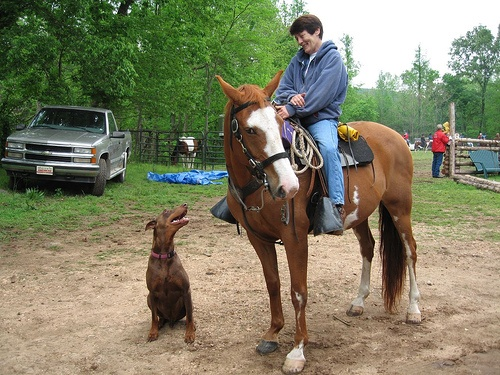

Blob Visualization:


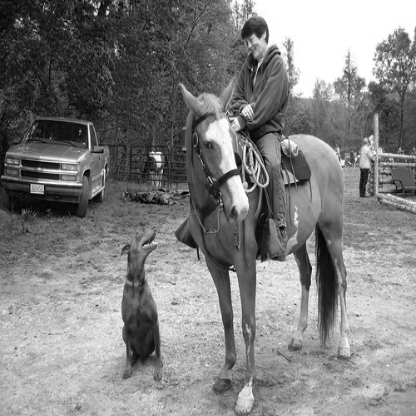

Blob shape=(1, 3, 416, 416)
Forward propagation time = 2.5421 seconds
Detection completed successfully!


In [ ]:
# Downgrade OpenCV to a stable 4.x version to restore the Darknet importer
!pip install -q "opencv-python>=4.8.0,<5.0.0" "opencv-python-headless>=4.8.0,<5.0.0"

# Download YOLO weights, config, and coco names if they do not exist
!wget -q -N https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3.cfg
!wget -q -N https://pjreddie.com/media/files/yolov3.weights
!wget -q -N https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names

# YOLO object detection
import cv2 as cv
import numpy as np
import time
from google.colab.patches import cv2_imshow
import os

# Check if image exists, otherwise write a dummy image or use an existing one
image_path = '/content/horse.jpg'
if not os.path.exists(image_path):
    # Create a dummy dark image with a white square as a fallback
    img = np.zeros((416, 416, 3), dtype=np.uint8)
    cv.putText(img, 'Fallback Image', (50, 200), cv.FONT_HERSHEY_SIMPLEX, 1, (255, 255, 255), 2)
else:
    img = cv.imread(image_path)

print("Original Image:")
cv2_imshow(img)

# Give the configuration and weight files for the model and load the network using the robust readNet function
net = cv.dnn.readNet('yolov3.weights', 'yolov3.cfg')
net.setPreferableBackend(cv.dnn.DNN_BACKEND_OPENCV)
net.setPreferableTarget(cv.dnn.DNN_TARGET_CPU)

ln = net.getLayerNames()
# Compatibility layer output name extraction
try:
    unconnected_layers = net.getUnconnectedOutLayers()
    if len(unconnected_layers.shape) == 1:
        out_names = [ln[i - 1] for i in unconnected_layers]
    else:
        out_names = [ln[i[0] - 1] for i in unconnected_layers]
except Exception:
    out_names = net.getUnconnectedOutLayersNames()

# construct a blob from the image
blob = cv.dnn.blobFromImage(img, 1/255.0, (416, 416), swapRB=True, crop=False)
r = blob[0, 0, :, :]

print("Blob Visualization:")
cv2_imshow(r * 255)
print(f'Blob shape={blob.shape}')

net.setInput(blob)
t0 = time.time()
outputs = net.forward(out_names)
t = time.time()

print(f'Forward propagation time = {t-t0:.4f} seconds')
print("Detection completed successfully!")

In [ ]:
net.setInput(blob)
t0 = time.time()
outputs = net.forward(ln)
t = time.time()

In [ ]:
net.setInput(blob)
outputs = net.forward(ln)

Forward pass: 1.87 s


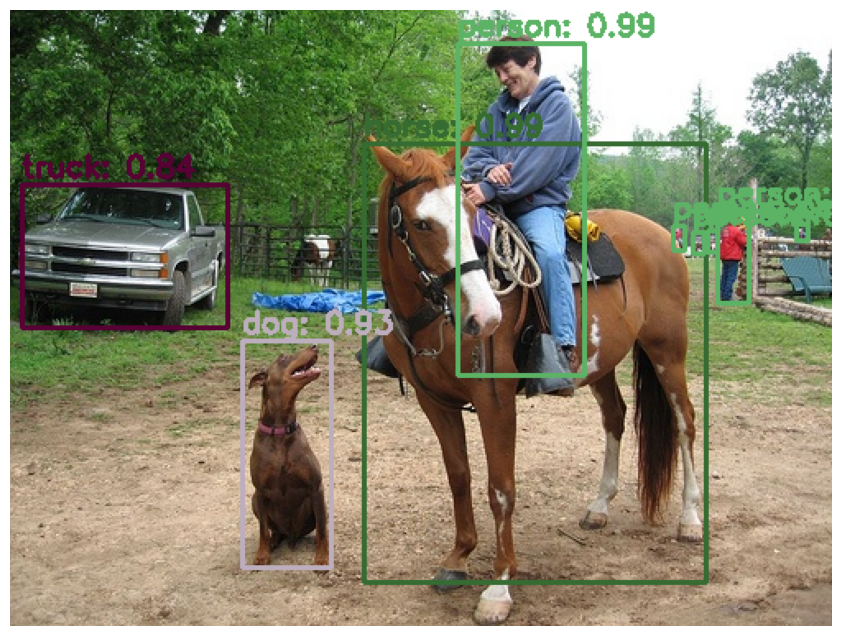

In [ ]:
# Download YOLOv3 files (skips anything already downloaded)
!mkdir -p images
!wget -nc -q https://raw.githubusercontent.com/pjreddie/darknet/master/cfg/yolov3.cfg
!wget -nc -q https://raw.githubusercontent.com/pjreddie/darknet/master/data/coco.names
!wget -nc -q https://pjreddie.com/media/files/yolov3.weights
!wget -nc -q -O images/horse.jpg https://raw.githubusercontent.com/pjreddie/darknet/master/data/horses.jpg

import cv2 as cv
import numpy as np
import matplotlib.pyplot as plt
import time

# Load image, class names, and network
img = cv.imread('/content/horse.jpg')
H, W = img.shape[:2]
classes = open('coco.names').read().strip().split('\n')
np.random.seed(42)
colors = np.random.randint(0, 255, size=(len(classes), 3)).tolist()

net = cv.dnn.readNetFromDarknet('yolov3.cfg', 'yolov3.weights')
net.setPreferableBackend(cv.dnn.DNN_BACKEND_OPENCV)
ln = net.getUnconnectedOutLayersNames()   # only the 3 YOLO output layers

# Run detection
blob = cv.dnn.blobFromImage(img, 1/255.0, (416, 416), swapRB=True, crop=False)
net.setInput(blob)
t0 = time.time()
outputs = np.vstack(net.forward(ln))
print(f'Forward pass: {time.time() - t0:.2f} s')

# Collect boxes above 50% confidence
boxes, confidences, class_ids = [], [], []
for det in outputs:
    scores = det[5:]
    cid = int(np.argmax(scores))
    conf = float(scores[cid])
    if conf > 0.5:
        cx, cy, w, h = det[:4] * np.array([W, H, W, H])
        boxes.append([int(cx - w/2), int(cy - h/2), int(w), int(h)])
        confidences.append(conf)
        class_ids.append(cid)

# Remove overlapping duplicate boxes, then draw
idxs = cv.dnn.NMSBoxes(boxes, confidences, 0.5, 0.4)
for i in np.array(idxs).flatten():
    x, y, w, h = boxes[i]
    color = colors[class_ids[i]]
    cv.rectangle(img, (x, y), (x + w, y + h), color, 2)
    label = f'{classes[class_ids[i]]}: {confidences[i]:.2f}'
    cv.putText(img, label, (x, y - 5), cv.FONT_HERSHEY_SIMPLEX, 0.6, color, 2)

# Show it (BGR -> RGB for matplotlib)
plt.figure(figsize=[12, 8])
plt.imshow(img[:, :, ::-1])
plt.axis('off');

In [ ]:
# Make a copy of the original image.
image_text = image.copy()

# Add text to the image.
text = 'Apollo 8 Saturn V Launch, 21 Dec 1968'
font_face = cv2.FONT_HERSHEY_SIMPLEX
font_scale = 0.8
font_color = green
font_thickness = 1

In [ ]:
image_text = cv2.putText(image_text, text, (45, 30), font_face, font_scale, font_color, font_thickness, cv2.LINE_AA)

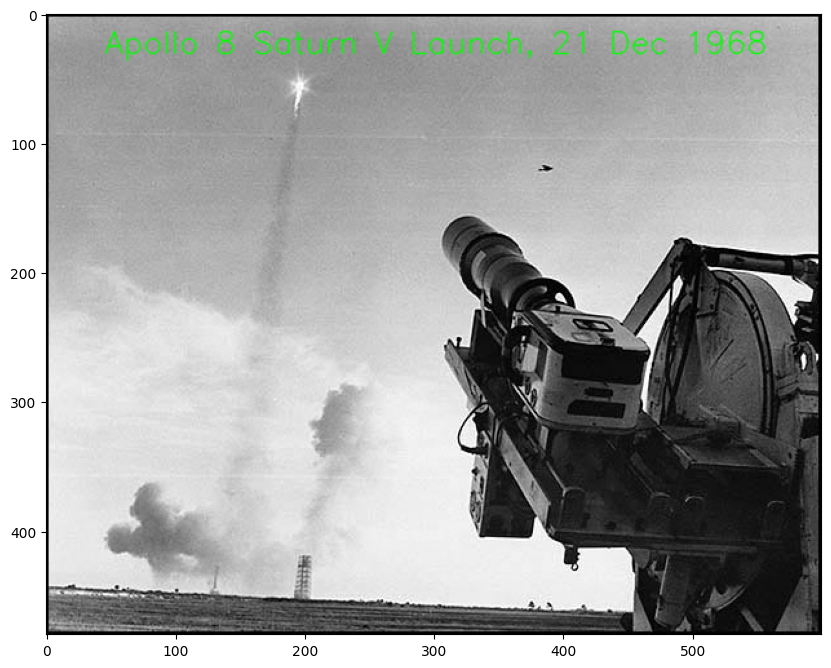

In [ ]:
# Display the annotated image.
plt.figure(figsize = [10, 10])
plt.imshow(image_text[:, :, ::-1]);

In [ ]:
# Read in the image ('Apollo-11-launch.jpg').
# ALSO - ADD YOUR OWN IMAGES!!!!
# Add the following text to the dark area at the bottom of the image (centered on the image):
# 'Apollo 11 Saturn V Launch, July 16, 1969'.
text = 'Apollo 11 Saturn V Launch, July 16, 1969'
font_face = cv2.FONT_HERSHEY_PLAIN

# YOUR CODE HERE: use putText()

# Draw a magenta rectangle that encompasses the launch tower and the rocket.
rect_color = magenta
# YOUR CODE HERE

# plt.figure(figsize=[12, 12])
# Display the final annotated image
# YOUR CODE HERE

# Matrix Algebra

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
from IPython.display import Image

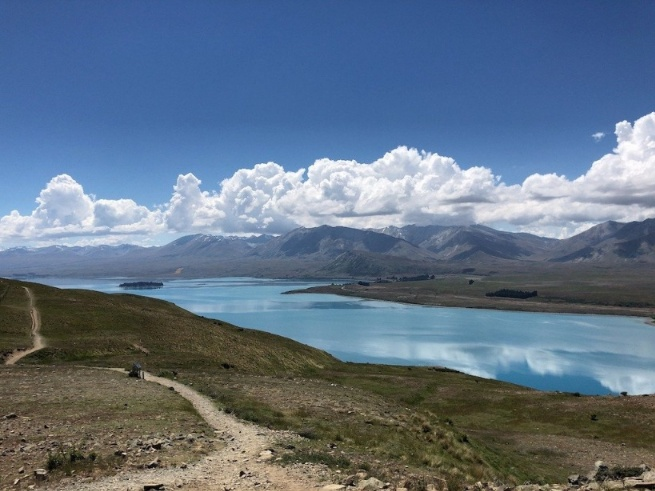

In [ ]:
image = '/content/cv2/Mod2/new-zealand-lake.jpg'
img = cv2.imread(image, cv2.IMREAD_COLOR)

# Display the image.
Image(filename=image, width='400')

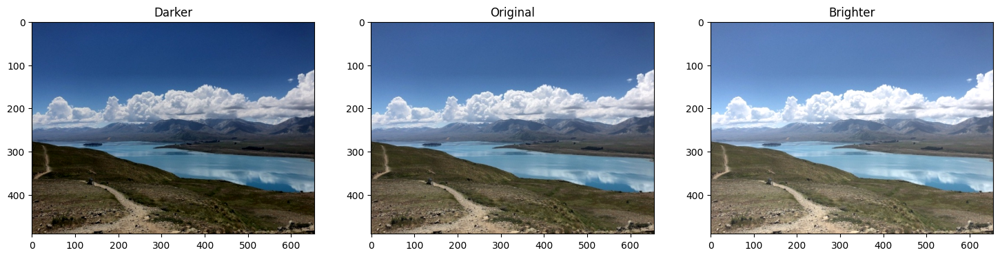

In [ ]:
# Create a matrix with constant intensity.
matrix = np.ones(img.shape, dtype = 'uint8') * 30

# Create brighter and darker images.
img_brighter = cv2.add(img, matrix)
img_darker   = cv2.subtract(img, matrix)

# Display the images
plt.figure(figsize = [18,5])
plt.subplot(131); plt.imshow(img_darker[:, :, ::-1]);   plt.title('Darker')
plt.subplot(132); plt.imshow(img[:, :, ::-1]);          plt.title('Original')
plt.subplot(133); plt.imshow(img_brighter[:, :, ::-1]); plt.title('Brighter');

In [ ]:
# Two pixels: one medium, one already bright.
pixels = np.array([[200, 250]], dtype = 'uint8')
boost  = np.array([[30, 30]],   dtype = 'uint8')

print('NumPy  + :', pixels + boost)
print('OpenCV add:', cv2.add(pixels, boost))

NumPy  + : [[230  24]]
OpenCV add: [[230 255]]


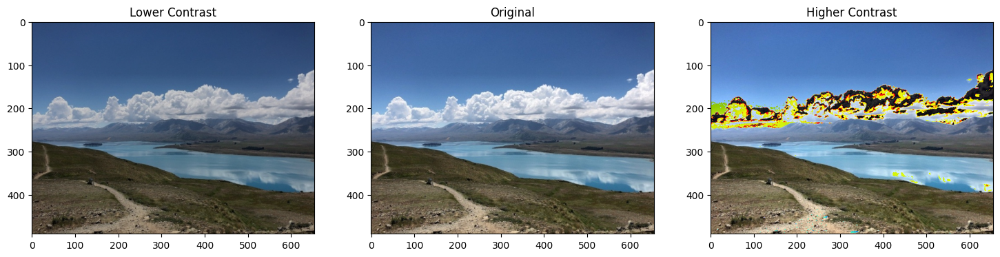

In [ ]:
# Create matrices with a constant scale factor.
matrix1 = np.ones(img.shape) * 0.8
matrix2 = np.ones(img.shape) * 1.2

# Create lower and higher contrast images.
img_lower  = np.uint8(cv2.multiply(np.float64(img), matrix1))
img_higher = np.uint8(cv2.multiply(np.float64(img), matrix2))

# Display the images.
plt.figure(figsize = [18,5])
plt.subplot(131); plt.imshow(img_lower[:, :, ::-1]);  plt.title('Lower Contrast')
plt.subplot(132); plt.imshow(img[:, :, ::-1]);        plt.title('Original')
plt.subplot(133); plt.imshow(img_higher[:, :, ::-1]); plt.title('Higher Contrast');

In [ ]:
# Three pixel values, stretched by 1.2 in floating point.
values  = np.array([[150.0, 100.0, 230.0]])
stretch = cv2.multiply(values, np.ones(values.shape) * 1.2)

print('As floats       :', stretch)
print('np.uint8()      :', np.uint8(stretch))
print('Clip, then uint8:', np.uint8(np.clip(stretch, 0, 255)))

As floats       : [[180. 120. 276.]]
np.uint8()      : [[180 120  20]]
Clip, then uint8: [[180 120 255]]


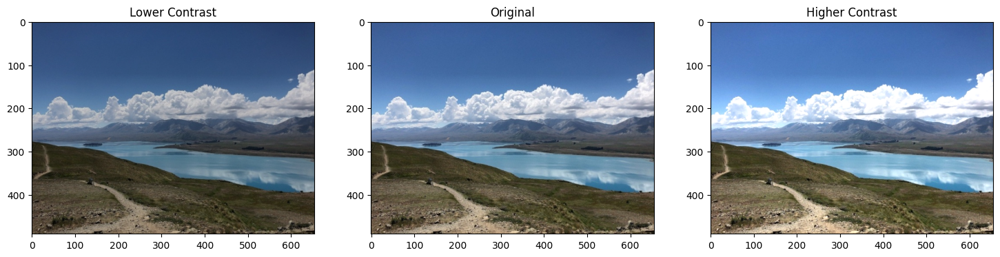

In [ ]:
# Create matrices with a constant scale factor.
matrix1 = np.ones(img.shape) * 0.8
matrix2 = np.ones(img.shape) * 1.2

# Create lower and higher contrast images.
img_lower   = np.uint8(cv2.multiply(np.float64(img), matrix1))
img_higher  = np.uint8(np.clip(cv2.multiply(np.float64(img), matrix2) , 0, 255))

# Display the images.
plt.figure(figsize=[18,5])
plt.subplot(131); plt.imshow(img_lower[:, :, ::-1]);  plt.title('Lower Contrast')
plt.subplot(132); plt.imshow(img[:, :, ::-1]);        plt.title('Original')
plt.subplot(133); plt.imshow(img_higher[:, :, ::-1]); plt.title('Higher Contrast');

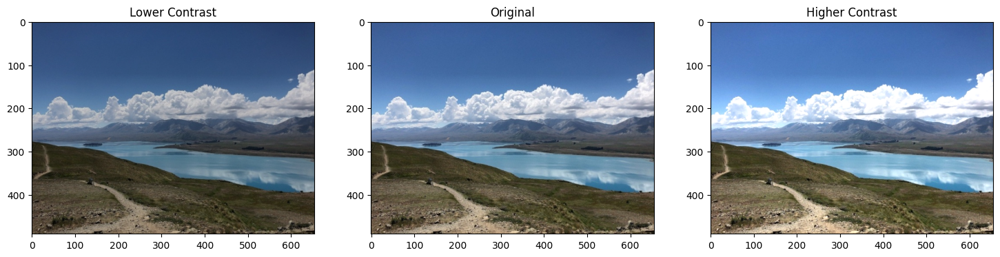

In [ ]:
# Create matrices with a constant scale factor.
matrix_ones = np.ones(img.shape, dtype = 'float64')

# Create lower and higher contrast images.
img_lower   = np.uint8(cv2.multiply(np.float64(img), matrix_ones, scale = 0.8))
img_higher  = np.uint8(np.clip(cv2.multiply(np.float64(img), matrix_ones, scale = 1.2) , 0, 255))

# Display the images.
plt.figure(figsize = [18,5])
plt.subplot(131); plt.imshow(img_lower[:, :, ::-1]);  plt.title('Lower Contrast')
plt.subplot(132); plt.imshow(img[:, :, ::-1]);        plt.title('Original')
plt.subplot(133); plt.imshow(img_higher[:, :, ::-1]); plt.title('Higher Contrast');

In [ ]:
# Read the image ('Santorini.jpg')
# FOR YOU.. OR - USE ANY IMAGE
image = 'Santorini.jpg'
img = cv2.imread(image, cv2.IMREAD_COLOR)

# Create a matrix of ones (with data type float64)
# matrix_ones =

# Create two higher contrast images using the 'scale' option with factors of 1.1 and 1.2 (without overflow fix)
# YOUR CODE HERE
# img_higher1  =
# img_higher2  =

# Display the images (original, higher (1.1x) , high (1.2x))
# UNCOMMENT the lines below.
# plt.figure(figsize=[18,5])
# plt.subplot(131); plt.imshow(img[:, :, ::-1]);         plt.title('Original')
# plt.subplot(132); plt.imshow(img_higher1[:, :, ::-1]); plt.title('Higher (1.1x)')
# plt.subplot(133); plt.imshow(img_higher2[:, :, ::-1]); plt.title('Higher (1.2x)');

# Create higher contrast images using scale factors of 1.1 and 1.2 (using np.clip() to clip high values to 255)
# YOUR CODE HERE
# img_higher1  =
# img_higher2  =

# Display the images (original, higher (1.1x) clipped , high (1.2x) clipped)
# UNCOMMENT the lines below.
# plt.figure(figsize = [18,5])
# plt.subplot(131); plt.imshow(img[:, :, ::-1]);         plt.title('Original')
# plt.subplot(132); plt.imshow(img_higher1[:, :, ::-1]); plt.title('Higher (1.1x): clipped')
# plt.subplot(133); plt.imshow(img_higher2[:, :, ::-1]); plt.title('Higher (1.2x): clipped');

# Thresholding Images with OpenCV

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline
plt.rcParams['image.cmap'] = 'gray'

In [ ]:
# Five pixel brightness values, from dark to bright.
pixels = np.array([[100, 164, 165, 166, 250]], dtype = 'uint8')

retval, binary     = cv2.threshold(pixels, 165, 255, cv2.THRESH_BINARY)
retval, binary_inv = cv2.threshold(pixels, 165, 255, cv2.THRESH_BINARY_INV)

print('retval        :', retval)
print('Original      :', pixels)
print('THRESH_BINARY :', binary)
print('BINARY_INV    :', binary_inv)

retval        : 165.0
Original      : [[100 164 165 166 250]]
THRESH_BINARY : [[  0   0   0 255 255]]
BINARY_INV    : [[255 255 255   0   0]]


Text(0.5, 1.0, 'Thresholded')

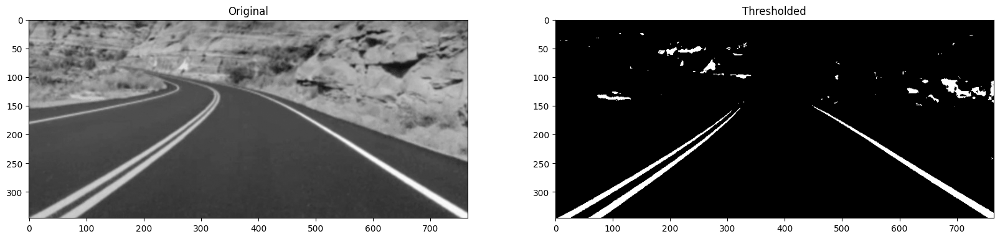

In [ ]:
# Read image in grayscale.
img = cv2.imread('/content/cv2/Mod2/road_lanes.png', cv2.IMREAD_GRAYSCALE)

# Perform binary thresholding.
retval, img_thresh = cv2.threshold(img, 165, 100, cv2.THRESH_BINARY)

# Display the images.
plt.figure(figsize = [20, 8])
plt.subplot(121); plt.imshow(img); plt.title('Original')
plt.subplot(122); plt.imshow(img_thresh); plt.title('Thresholded')

Text(0.5, 1.0, 'Thresholded')

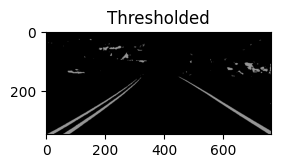

In [ ]:
plt.subplot(122); plt.imshow(img_thresh, cmap='gray', vmin=0, vmax=255); plt.title('Thresholded')

In [ ]:
# Read the original image.
img = cv2.imread('/content/cv2/Mod2/Piano_Sheet_Music.png', cv2.IMREAD_GRAYSCALE)

# Perform global thresholding.
retval, img_thresh_gbl_1 = cv2.threshold(img, 50, 255, cv2.THRESH_BINARY)

# Perform global thresholding.
retval, img_thresh_gbl_2 = cv2.threshold(img, 130, 255, cv2.THRESH_BINARY)

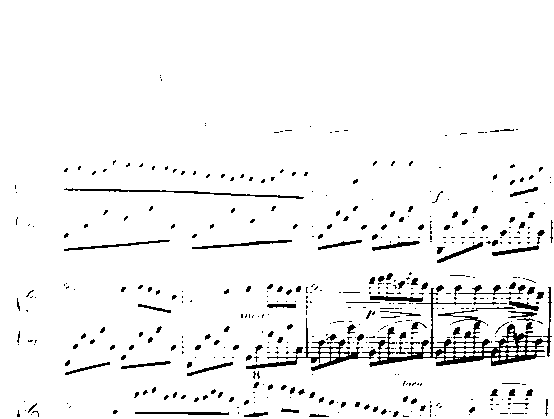

In [ ]:
from google.colab.patches import cv2_imshow
cv2_imshow(img_thresh_gbl_1)

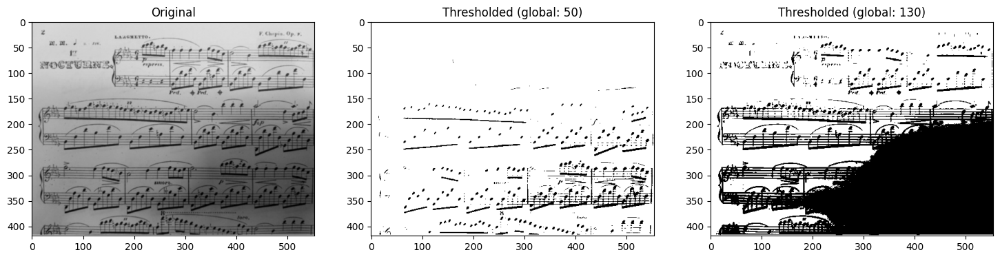

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=[18, 5])
plt.subplot(131); plt.imshow(img, cmap='gray');              plt.title('Original')
plt.subplot(132); plt.imshow(img_thresh_gbl_1, cmap='gray'); plt.title('Thresholded (global: 50)')
plt.subplot(133); plt.imshow(img_thresh_gbl_2, cmap='gray'); plt.title('Thresholded (global: 130)')
plt.show()

In [ ]:
# Perform adaptive thresholding.
img_thresh_adp = cv2.adaptiveThreshold(img, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 13, 7)

Text(0.5, 1.0, 'Thresholded (adaptive)')

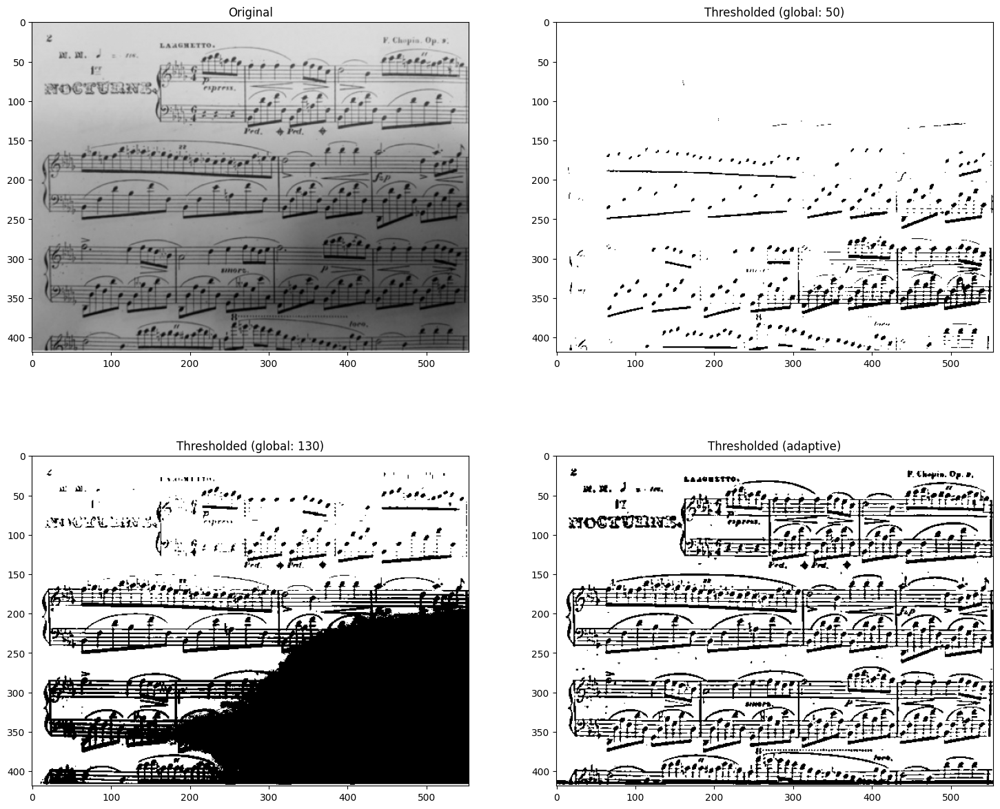

In [ ]:
# Display the images.
plt.figure(figsize = [18, 15])
plt.subplot(221); plt.imshow(img);              plt.title('Original')
plt.subplot(222); plt.imshow(img_thresh_gbl_1); plt.title('Thresholded (global: 50)')
plt.subplot(223); plt.imshow(img_thresh_gbl_2); plt.title('Thresholded (global: 130)')
plt.subplot(224); plt.imshow(img_thresh_adp);   plt.title('Thresholded (adaptive)')

In [ ]:
img = cv2.imread('Sheet_Music_Test-1.jpg', cv2.IMREAD_GRAYSCALE)
# Or pick your own IMAGE!
# Perform global thresholding (find the best global threshold that isolates the music from the shadows).
# Use a threshold type of: cv2.THRESH_BINARY_INV
# YOUR CODE HERE
# retval, img_thresh =

# Display the images.
# UNCOMMENT the lines below.
# plt.figure(figsize = [18,15])
# plt.subplot(121); plt.imshow(img);        plt.title('Original')
# plt.subplot(122); plt.imshow(img_thresh); plt.title('Thresholded (global)')

# Alpha Channel

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 25.8/25.8 MB 58.6 MB/s eta 0:00:00
/content/Lover Man.pdf: 1 page(s)
Rendered at 200 DPI: 1700 x 2200 pixels


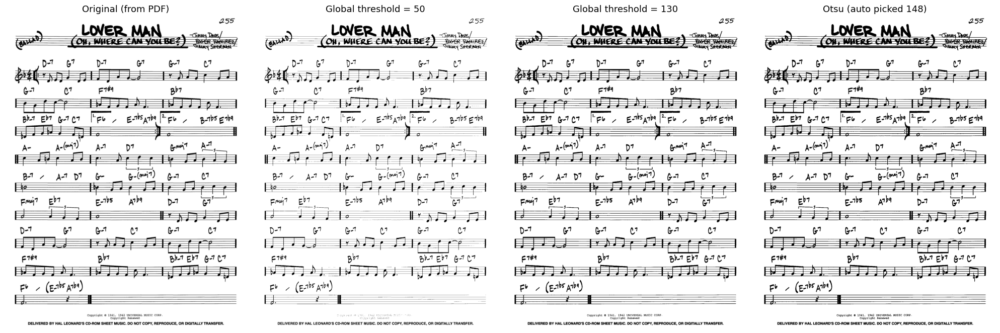

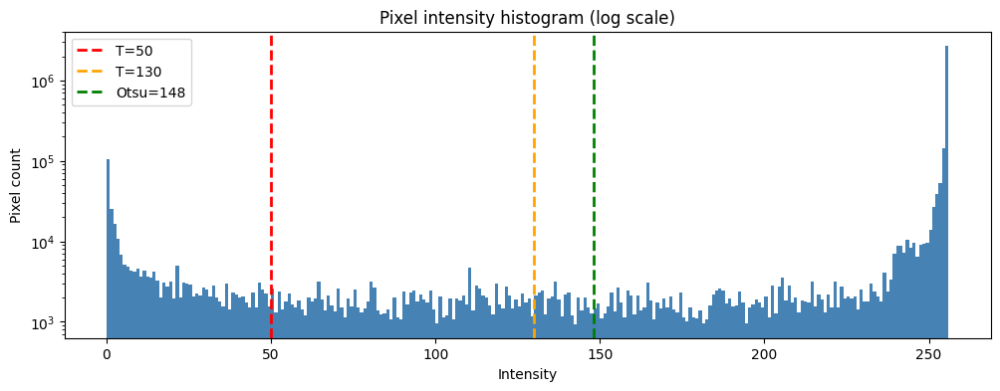

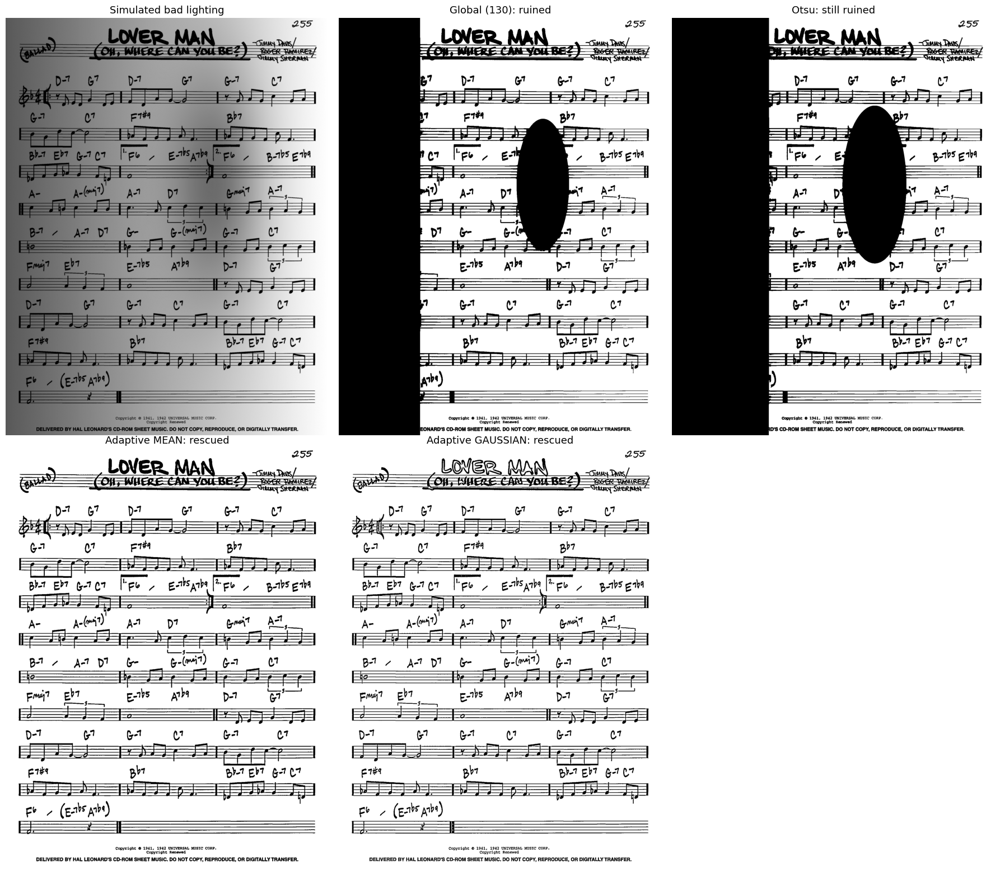

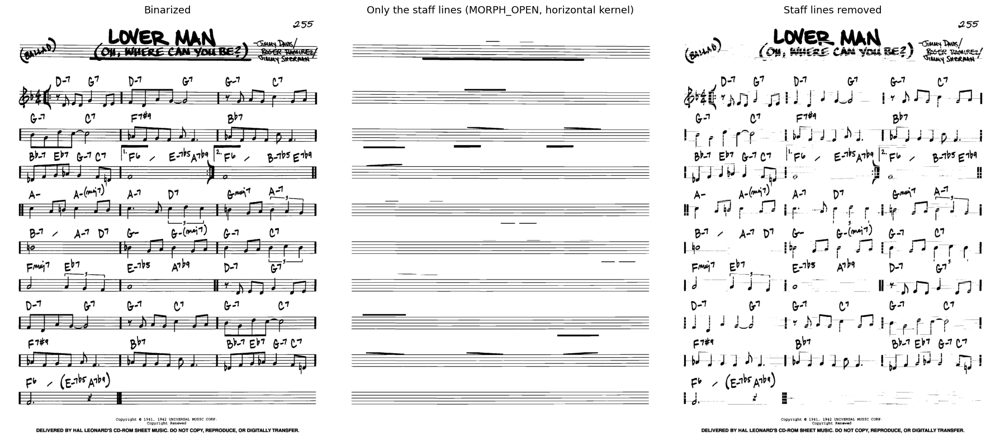

Detected 42 staff lines, which is about 8 staves


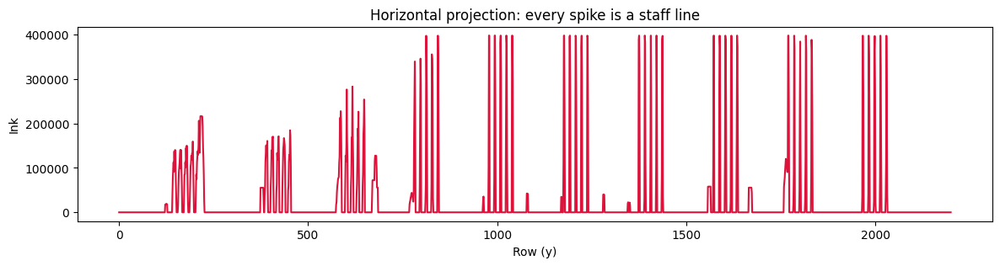

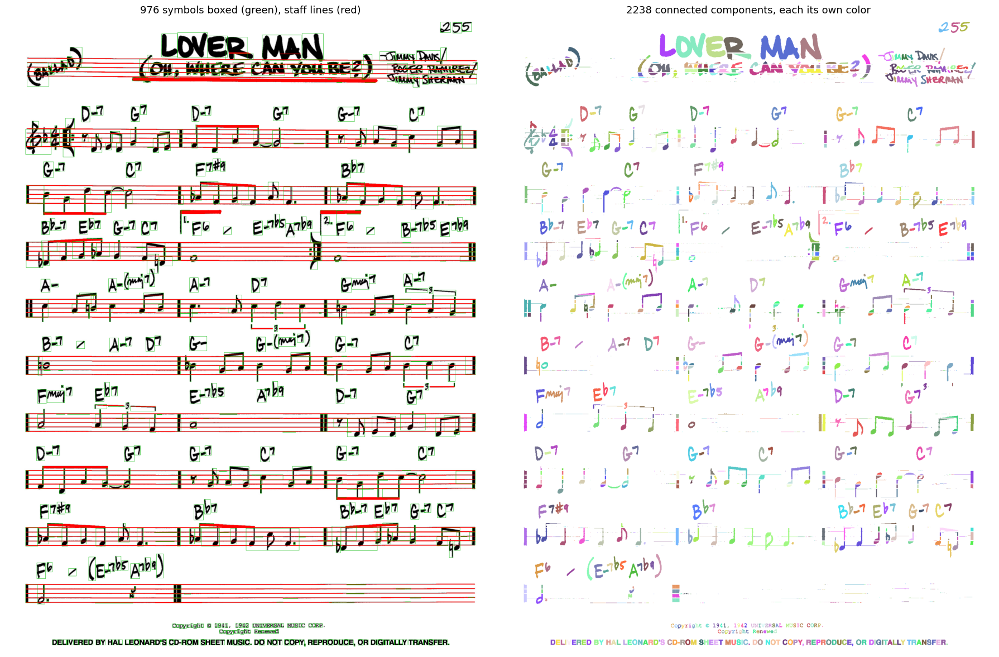

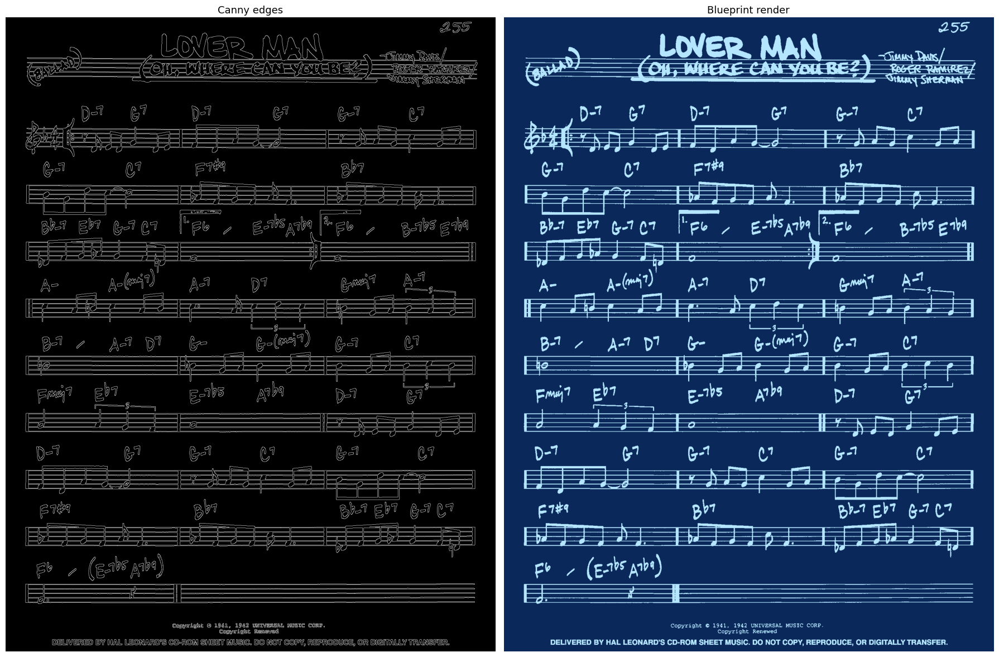

In [ ]:
!pip install -q pymupdf

import fitz  # PyMuPDF
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show(images, titles, cols=3, size=6):
    rows = int(np.ceil(len(images) / cols))
    plt.figure(figsize=[size * cols, size * 1.3 * rows])
    for i, (im, t) in enumerate(zip(images, titles)):
        plt.subplot(rows, cols, i + 1)
        if im.ndim == 2:
            plt.imshow(im, cmap='gray')
        else:
            plt.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB))
        plt.title(t, fontsize=13); plt.axis('off')
    plt.tight_layout(); plt.show()

# ------------------------------------------------------------
# 0. Render the PDF page to a grayscale image
# ------------------------------------------------------------
pdf_path = '/content/Lover Man.pdf'
doc = fitz.open(pdf_path)
print(f"{pdf_path}: {doc.page_count} page(s)")
page = doc[0]
pix = page.get_pixmap(dpi=200, colorspace=fitz.csGRAY)          # raise dpi for sharper detail
img = np.frombuffer(pix.samples, dtype=np.uint8).reshape(pix.height, pix.stride)[:, :pix.width].copy()
cv2.imwrite('Lover_Man.png', img)                              # handy if you want the PNG too
h, w = img.shape
print(f"Rendered at 200 DPI: {w} x {h} pixels")

# ------------------------------------------------------------
# 1. The two global thresholds + Otsu
# ------------------------------------------------------------
retval, img_thresh_gbl_1 = cv2.threshold(img, 50, 255, cv2.THRESH_BINARY)
retval, img_thresh_gbl_2 = cv2.threshold(img, 130, 255, cv2.THRESH_BINARY)
otsu_val, img_otsu = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)

show([img, img_thresh_gbl_1, img_thresh_gbl_2, img_otsu],
     ['Original (from PDF)', 'Global threshold = 50', 'Global threshold = 130', f'Otsu (auto picked {otsu_val:.0f})'],
     cols=4, size=5)

# ------------------------------------------------------------
# 2. The histogram: why Otsu lands where it does
# ------------------------------------------------------------
plt.figure(figsize=[12, 4])
plt.hist(img.ravel(), bins=256, range=(0, 256), color='steelblue')
for t, c, lbl in [(50, 'red', 'T=50'), (130, 'orange', 'T=130'), (otsu_val, 'green', f'Otsu={otsu_val:.0f}')]:
    plt.axvline(t, color=c, linestyle='--', linewidth=2, label=lbl)
plt.yscale('log'); plt.legend(); plt.title('Pixel intensity histogram (log scale)')
plt.xlabel('Intensity'); plt.ylabel('Pixel count'); plt.show()

# ------------------------------------------------------------
# 3. THE WOW MOMENT: simulate a bad phone photo (uneven light + shadow)
# ------------------------------------------------------------
xx, yy = np.meshgrid(np.linspace(0, 1, w), np.linspace(0, 1, h))
lighting = 0.35 + 0.65 * xx
shadow = 1 - 0.45 * np.exp(-(((xx - 0.65) ** 2) / 0.02 + ((yy - 0.4) ** 2) / 0.08))
img_bad = np.clip(img.astype(np.float32) * lighting * shadow, 0, 255).astype(np.uint8)

_, bad_global = cv2.threshold(img_bad, 130, 255, cv2.THRESH_BINARY)
_, bad_otsu = cv2.threshold(img_bad, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
bad_adapt_mean = cv2.adaptiveThreshold(img_bad, 255, cv2.ADAPTIVE_THRESH_MEAN_C, cv2.THRESH_BINARY, 25, 10)
bad_adapt_gauss = cv2.adaptiveThreshold(img_bad, 255, cv2.ADAPTIVE_THRESH_GAUSSIAN_C, cv2.THRESH_BINARY, 25, 10)

show([img_bad, bad_global, bad_otsu, bad_adapt_mean, bad_adapt_gauss],
     ['Simulated bad lighting', 'Global (130): ruined', 'Otsu: still ruined',
      'Adaptive MEAN: rescued', 'Adaptive GAUSSIAN: rescued'],
     cols=3, size=6)

# ------------------------------------------------------------
# 4. Morphology: pull the staff lines out of the music
# ------------------------------------------------------------
_, inv = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

horiz_kernel = cv2.getStructuringElement(cv2.MORPH_RECT, (w // 25, 1))
staff_lines = cv2.morphologyEx(inv, cv2.MORPH_OPEN, horiz_kernel)

symbols = cv2.subtract(inv, staff_lines)
symbols = cv2.morphologyEx(symbols, cv2.MORPH_CLOSE,
                           cv2.getStructuringElement(cv2.MORPH_RECT, (1, 3)))

show([255 - inv, 255 - staff_lines, 255 - symbols],
     ['Binarized', 'Only the staff lines (MORPH_OPEN, horizontal kernel)', 'Staff lines removed'],
     cols=3, size=6)

# ------------------------------------------------------------
# 5. Count the staff lines and staves from a row projection
# ------------------------------------------------------------
row_profile = staff_lines.sum(axis=1)
line_rows = np.where(row_profile > 0.5 * row_profile.max())[0]
lines = []
for r in line_rows:
    if not lines or r - lines[-1][-1] > 2:
        lines.append([r])
    else:
        lines[-1].append(r)
line_centers = [int(np.mean(l)) for l in lines]
print(f"Detected {len(line_centers)} staff lines, which is about {len(line_centers) // 5} staves")

plt.figure(figsize=[14, 3])
plt.plot(row_profile, color='crimson'); plt.title('Horizontal projection: every spike is a staff line')
plt.xlabel('Row (y)'); plt.ylabel('Ink'); plt.show()

# ------------------------------------------------------------
# 6. Connected components: find and box every musical symbol
# ------------------------------------------------------------
n, labels, stats, centroids = cv2.connectedComponentsWithStats(symbols, connectivity=8)

overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
overlay[staff_lines > 0] = (0, 0, 255)
count = 0
for i in range(1, n):
    x, y, bw, bh, area = stats[i]
    if 15 < area < 0.02 * h * w:
        cv2.rectangle(overlay, (x, y), (x + bw, y + bh), (0, 180, 0), 1)
        count += 1

rng = np.random.default_rng(7)
palette = rng.integers(60, 255, size=(n, 3), dtype=np.uint8); palette[0] = 255
colored = palette[labels]

show([overlay, colored],
     [f'{count} symbols boxed (green), staff lines (red)', f'{n - 1} connected components, each its own color'],
     cols=2, size=9)

# ------------------------------------------------------------
# 7. Bonus: edges, and a "blueprint" look for the finale
# ------------------------------------------------------------
edges = cv2.Canny(img, 50, 150)
blueprint = np.zeros((h, w, 3), np.uint8); blueprint[:] = (90, 40, 10)
blueprint[inv > 0] = (255, 230, 180)
show([edges, blueprint], ['Canny edges', 'Blueprint render'], cols=2, size=9)

Found 8 staves, line thickness ~3px
Staff  1: G4  D5  C5  E5  C5  A4  G5  F4  G4  F4  A4  F4  A4  D6  F4  G4  F4  C5  F4
Staff  2: D6  D4  F4  G4  D6  A4  G4  C6  F4  D4  D4  F4  D6  F4  C6
Staff  3: C5  A4  Bb4  Bb4  C5  A4  Bb4  C5  A4  C5  C6  D5  C5  Bb4  C6  G4  A4  Bb4  A4  G4
Staff  4: C6  D6  C6  Bb4  G4  A4  Bb4  G4  A4  Bb4  G4  A4  Bb4  C5  Bb4
Staff  5: A4  A4  G4  F4  A4  C5  D4  E4  D4  G4  D4  E4  Bb4
Staff  6: F4  D4  A4  G4  G4  D6  D6  G4  A4  G4  C5  G4  A4  Bb4  G4  D5  C5  C5
Staff  7: A4  F4  G4  F4  A4  F4  A4  C6  F4  G4  F4  C5  F4  D4  D6  F4  G4  A4  G4  D6  F4  E5  D4  D4
Staff  8: F4  Bb5


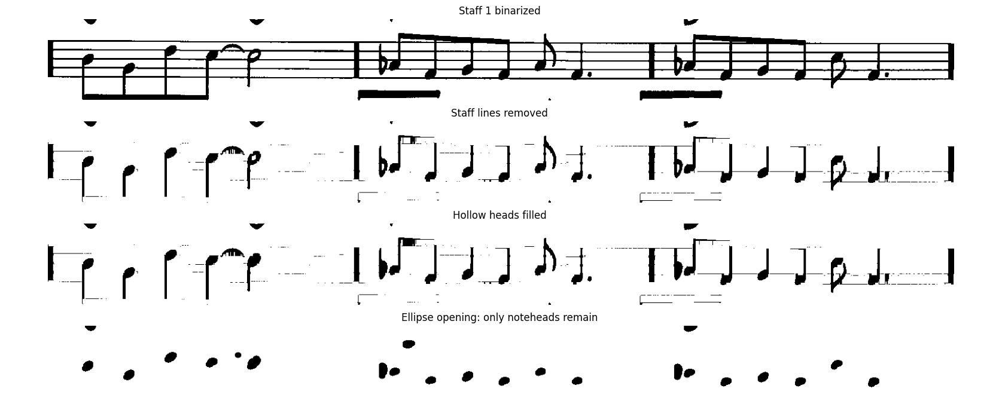

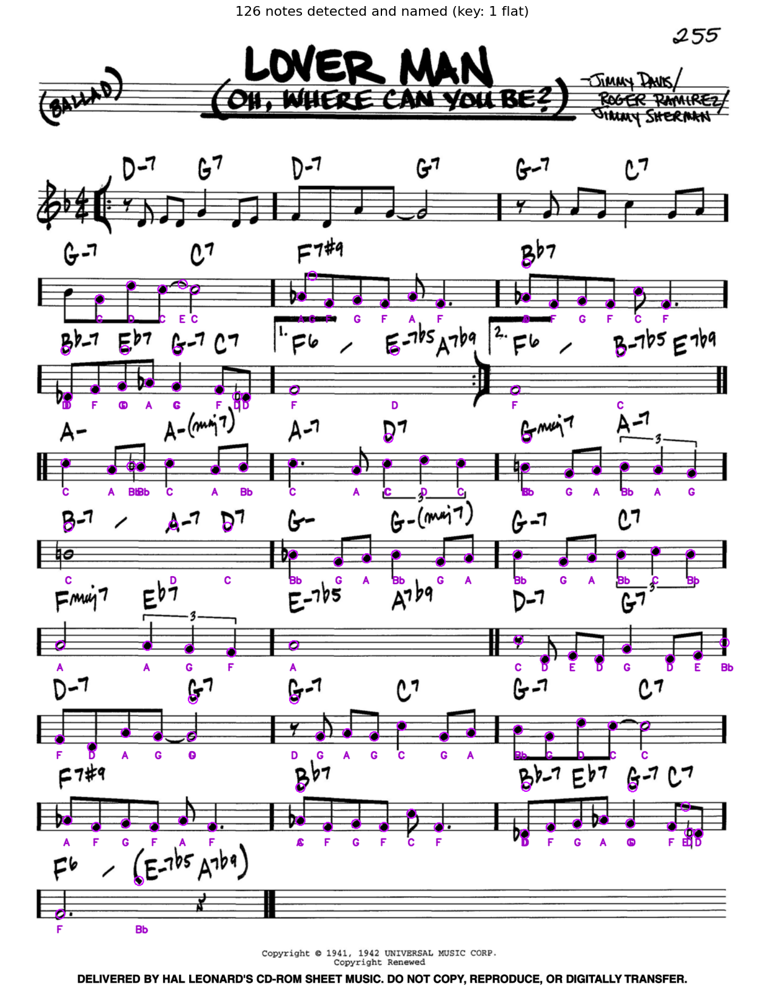

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import Audio, display

# ============================================================
# NOTE NAMER: a mini optical music recognition (OMR) pipeline
# ============================================================
KEY_FLATS = {'B'}          # key signature: Lover Man is in F major (one flat, Bb)
HEAD_KERNEL_FRAC = 0.75    # notehead "stamp" size relative to staff spacing (tune 0.6 to 0.9)
CLEF_ZONE_SP = 7           # ignore this many staff-spaces at the start of staff 1 (clef, key, time sig)

LETTERS = ['C', 'D', 'E', 'F', 'G', 'A', 'B']
SEMIS = {'C': 0, 'D': 2, 'E': 4, 'F': 5, 'G': 7, 'A': 9, 'B': 11}

# ---------- 1. Binarize and find staff lines ----------
_, inv = cv2.threshold(img, 0, 255, cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)
h, w = inv.shape
staff_mask = cv2.morphologyEx(inv, cv2.MORPH_OPEN,
                              cv2.getStructuringElement(cv2.MORPH_RECT, (w // 25, 1)))
prof = staff_mask.sum(axis=1)
rows = np.where(prof > 0.5 * prof.max())[0]
groups = []
for r in rows:
    if not groups or r - groups[-1][-1] > 2:
        groups.append([r])
    else:
        groups[-1].append(r)
centers = np.array([np.mean(g) for g in groups])
line_thick = int(np.ceil(np.mean([len(g) for g in groups])))

# ---------- 2. Group lines into 5-line staves ----------
staves, i = [], 0
while i + 5 <= len(centers):
    five = centers[i:i + 5]
    d = np.diff(five)
    if d.max() < 1.5 * d.min():          # evenly spaced = a real staff
        staves.append(five); i += 5
    else:
        i += 1
print(f"Found {len(staves)} staves, line thickness ~{line_thick}px")

# ---------- 3. Remove staff lines, heal the cuts, fill hollow heads ----------
no_staff = cv2.subtract(inv, staff_mask)
no_staff = cv2.morphologyEx(no_staff, cv2.MORPH_CLOSE,
                            cv2.getStructuringElement(cv2.MORPH_RECT, (1, 2 * line_thick + 1)))
filled = np.zeros_like(no_staff)
contours, _ = cv2.findContours(no_staff, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
cv2.drawContours(filled, contours, -1, 255, thickness=cv2.FILLED)   # half notes become solid ovals

# ---------- 4. Per staff: stamp out noteheads and read their pitch ----------
def pitch_name(step):
    """step 0 = bottom line of treble staff (E4), each step = one line or space."""
    idx = 4 * 7 + 2 + step                # E4 as a diatonic index
    letter, octave = LETTERS[idx % 7], idx // 7
    flat = letter in KEY_FLATS
    return letter + ('b' if flat else ''), octave, 12 * (octave + 1) + SEMIS[letter] - flat

overlay = cv2.cvtColor(img, cv2.COLOR_GRAY2BGR)
melody, demo_steps = [], None

for s, five in enumerate(staves):
    sp = np.mean(np.diff(five))
    top, bottom = five[0], five[4]
    y0, y1 = int(max(0, top - 2.5 * sp)), int(min(h, bottom + 2.5 * sp))

    k = max(3, int(HEAD_KERNEL_FRAC * sp))
    band = filled[y0:y1]
    heads = cv2.morphologyEx(band, cv2.MORPH_OPEN,
                             cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (k, k)))  # stems, beams, ties vanish
    if s == 0:
        demo_steps = (inv[y0:y1], no_staff[y0:y1], band, heads)

    xs = np.where(staff_mask[int(top):int(bottom) + 1].any(axis=0))[0]
    x_left = xs.min() if len(xs) else 0

    n, _, stats, cents = cv2.connectedComponentsWithStats(heads)
    found = []
    for j in range(1, n):
        x, y, bw, bh, area = stats[j]
        if not (0.35 * sp**2 < area < 2.5 * sp**2): continue
        if not (0.6 * sp < bw < 2.2 * sp and 0.5 * sp < bh < 1.7 * sp): continue
        cx, cy = cents[j][0], cents[j][1] + y0
        if s == 0 and cx < x_left + CLEF_ZONE_SP * sp: continue
        step = int(round((bottom - cy) / (sp / 2)))
        name, octave, midi = pitch_name(step)
        found.append((cx, cy, name, octave, midi))

    found.sort(key=lambda f: f[0])
    print(f"Staff {s + 1:>2}: " + "  ".join(f"{nm}{oc}" for _, _, nm, oc, _ in found))
    for cx, cy, name, octave, midi in found:
        melody.append(midi)
        cv2.circle(overlay, (int(cx), int(cy)), int(0.7 * sp), (255, 0, 200), 2)
        cv2.putText(overlay, name, (int(cx - 0.5 * sp), int(bottom + 2.2 * sp)),
                    cv2.FONT_HERSHEY_SIMPLEX, sp / 22, (200, 0, 160), 2, cv2.LINE_AA)

# ---------- 5. Show the pipeline on staff 1 ----------
titles = ['Staff 1 binarized', 'Staff lines removed', 'Hollow heads filled', 'Ellipse opening: only noteheads remain']
plt.figure(figsize=[18, 7])
for i, (im, t) in enumerate(zip(demo_steps, titles)):
    plt.subplot(4, 1, i + 1); plt.imshow(255 - im, cmap='gray'); plt.title(t); plt.axis('off')
plt.tight_layout(); plt.show()

# ---------- 6. The labeled page ----------
plt.figure(figsize=[16, 21])
plt.imshow(cv2.cvtColor(overlay, cv2.COLOR_BGR2RGB))
plt.title(f'{len(melody)} notes detected and named (key: {len(KEY_FLATS)} flat)', fontsize=16)
plt.axis('off'); plt.show()

# ---------- 7. Play it back ----------
sr, dur = 22050, 0.32
t = np.linspace(0, dur, int(sr * dur), endpoint=False)
env = np.minimum(1, t / 0.01) * np.exp(-3 * t)
tones = [env * (np.sin(2 * np.pi * f * t) + 0.3 * np.sin(4 * np.pi * f * t))
         for f in (440 * 2 ** ((m - 69) / 12) for m in melody)]
display(Audio(np.concatenate(tones) if tones else np.zeros(sr), rate=sr))

In [ ]:
import cv2
import numpy as np
from matplotlib import pyplot as plt
import matplotlib
%matplotlib inline
from IPython.display import Image
plt.rcParams['image.cmap'] = 'gray'

(2436, 2623, 4)


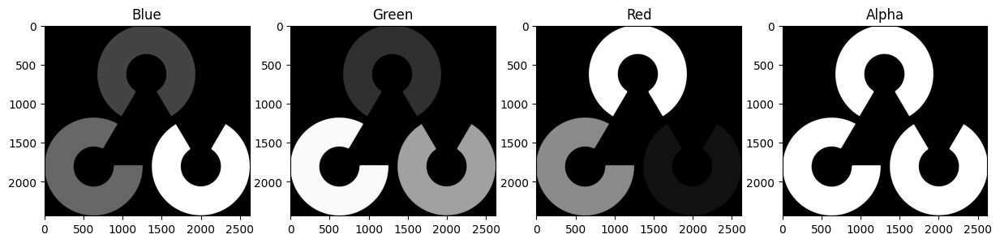

In [ ]:
# Read the PNG image using: cv2.IMREAD_UNCHANGED to retain the alpha channel.
img = cv2.imread('/content/cv2/Mod2/opencv_logo.png', cv2.IMREAD_UNCHANGED)

print(img.shape)

# Split the channels.
b, g, r, a = cv2.split(img)

# Display eazch of the channels.
plt.figure(figsize = (15,15))
plt.subplot(141); plt.imshow(b); plt.title('Blue')
plt.subplot(142); plt.imshow(g); plt.title('Green')
plt.subplot(143); plt.imshow(r); plt.title('Red')
plt.subplot(144); plt.imshow(a); plt.title('Alpha');

Shape of the color image:  (640, 640, 3)


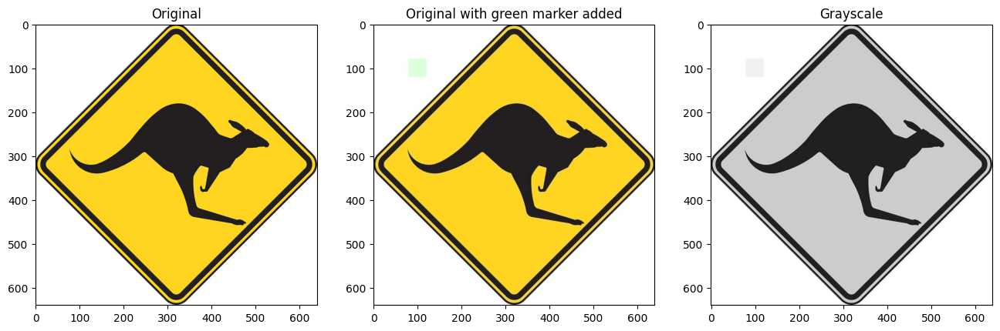

In [ ]:
# Read the original and modified JPG images of the kangaroo sign.
img_kang_org = cv2.imread("/content/cv2/Mod2/kangaroo.jpg",cv2.IMREAD_COLOR)
img_kang = cv2.imread('/content/cv2/Mod2/kangaroo_sign_with_green_marker.jpg',cv2.IMREAD_COLOR)

# For reference: Code used to add light green marker to original image of the kangaroo sign.
# img_kang_org[80:120,80:120,0] = 220
# img_kang_org[80:120,80:120,1] = 255
# img_kang_org[80:120,80:120,2] = 220
# cv2.imwrite('kangaroo_sign_with_green_marker.jpg', img_kang_org)

# Print the image shapes to verify the channels.
print('Shape of the color image: ', img_kang.shape)

# Convert the image to gray scale.
img_kang_gray = cv2.cvtColor(img_kang, cv2.COLOR_BGR2GRAY)

plt.figure(figsize = (16,10))
plt.subplot(131); plt.imshow(img_kang_org[:, :, ::-1]); plt.title('Original')
plt.subplot(132); plt.imshow(img_kang[:, :, ::-1]);     plt.title('Original with green marker added')
plt.subplot(133); plt.imshow(img_kang_gray);            plt.title('Grayscale');

In [ ]:
ret1, thresh1 = cv2.threshold(img_kang_gray, 150, 255, cv2.THRESH_BINARY)
ret2, thresh2 = cv2.threshold(img_kang_gray, 230, 255, cv2.THRESH_BINARY)
ret3, thresh3 = cv2.threshold(img_kang_gray, 230, 200, cv2.THRESH_BINARY)  # Note max value of mask is set to 200

In [ ]:
kang_inv_mask_full = cv2.bitwise_not(thresh2)  # Fully transparent
kang_inv_mask_semi = cv2.bitwise_not(thresh3)  # Semi-transparent (due to max value of thresh3 = 200)

# Print the pixel itensity of the inverted binary masks at the location (100,100).
print('Inverse Mask (full) at (100,100): ', kang_inv_mask_full[100,100])
print('Inverse Mask (semi) at (100,100): ', kang_inv_mask_semi[100,100])

Inverse Mask (full) at (100,100):  0
Inverse Mask (semi) at (100,100):  55


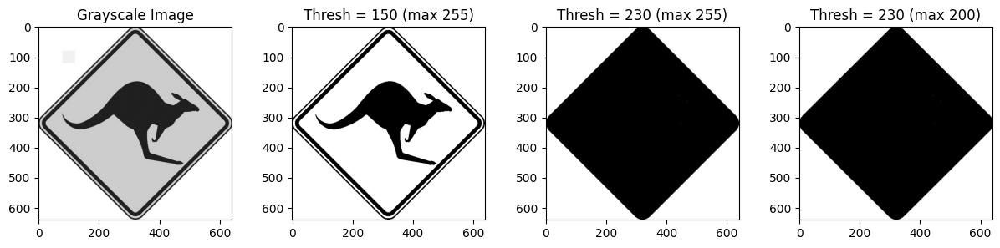

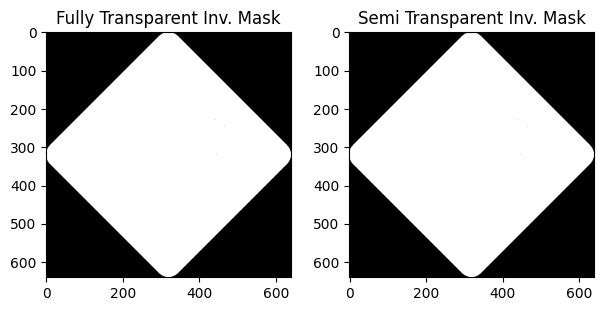

In [ ]:
plt.figure(figsize = (15, 3))
plt.subplot(141); plt.imshow(img_kang_gray);  plt.title('Grayscale Image')
plt.subplot(142); plt.imshow(thresh1); plt.title('Thresh = 150 (max 255)')
plt.subplot(143); plt.imshow(thresh2); plt.title('Thresh = 230 (max 255)')
plt.subplot(144); plt.imshow(thresh3); plt.title('Thresh = 230 (max 200)')

plt.figure(figsize = (15, 7))
plt.subplot(245); plt.imshow(kang_inv_mask_full); plt.title('Fully Transparent Inv. Mask')
plt.subplot(246); plt.imshow(kang_inv_mask_semi); plt.title('Semi Transparent Inv. Mask');

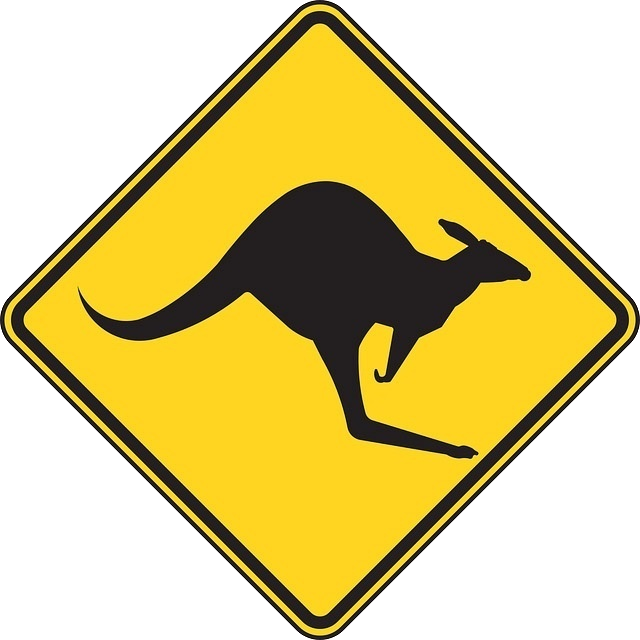

In [ ]:
# Split the color channels from the original image.
bk, gk, rk = cv2.split(img_kang)

# Add the "mask" as the 4th channel.
mat = [bk, gk, rk, kang_inv_mask_full]

# Use the merge() function to create a single multi-channel array.
kangaroo_transparent = cv2.merge(mat)

# Save the transparent image as a PNG file to preserve the alpha channel.
cv2.imwrite('kangaroo_alpha_full.png', kangaroo_transparent)

# Display the PNG file we just created.
Image(filename = "kangaroo_alpha_full.png", width = '300')

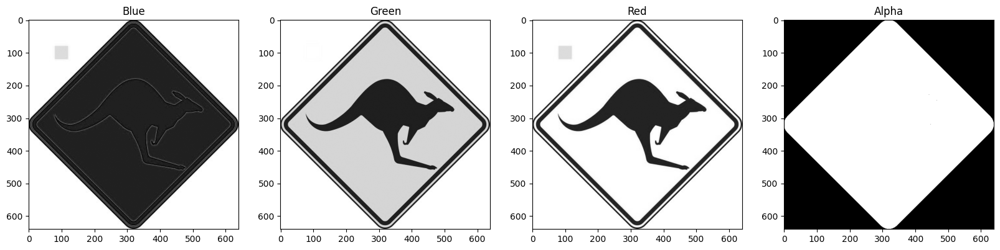

In [ ]:
# Read the PNG image using: cv2.IMREAD_UNCHANGED to retain the alpha channel.
img = cv2.imread('/content/cv2/Mod2/kangaroo_alpha_full.png', cv2.IMREAD_UNCHANGED)

# Split the channels.
b, g, r, a = cv2.split(img)

# Display each of the channels.
plt.figure(figsize = (20,15))
plt.subplot(141); plt.imshow(b); plt.title('Blue')
plt.subplot(142); plt.imshow(g); plt.title('Green')
plt.subplot(143); plt.imshow(r); plt.title('Red')
plt.subplot(144); plt.imshow(a); plt.title('Alpha');

Shape: (640, 640, 4)
Alpha at (100,100): 128


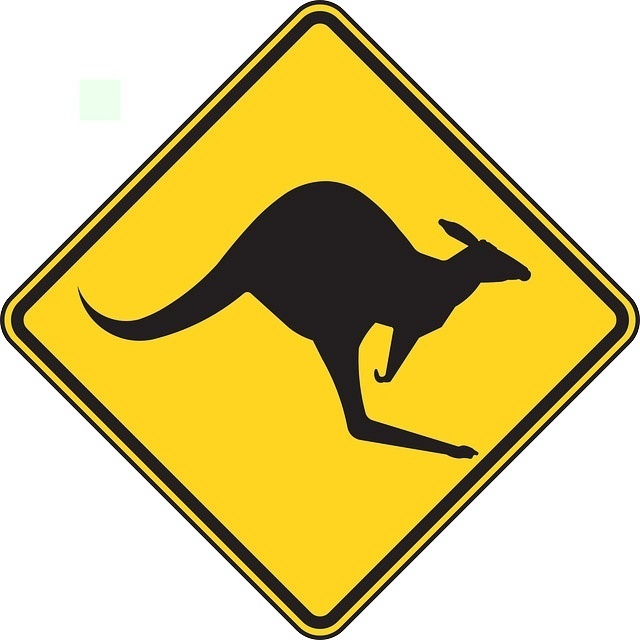

In [ ]:
# Threshold with a max value of 127, so that NOT gives 255 - 127 = 128 in the background.
# Or get your own image and use the alpha channel (get a png) and make the bg transparent
ret4, thresh4 = cv2.threshold(img_kang_gray, 230, 127, cv2.THRESH_BINARY)
kang_inv_mask_half = cv2.bitwise_not(thresh4)

# Attach the mask as the alpha channel and save as PNG.
bk, gk, rk = cv2.split(img_kang)
kangaroo_half = cv2.merge([bk, gk, rk, kang_inv_mask_half])
cv2.imwrite('kangaroo_alpha_half.png', kangaroo_half)

# Prove it: read the file back and check the alpha value in the background.
img_check = cv2.imread('kangaroo_alpha_half.png', cv2.IMREAD_UNCHANGED)
print('Shape:', img_check.shape)
print('Alpha at (100,100):', img_check[100, 100, 3])

# Display the PNG file we just created.
Image(filename = "kangaroo_alpha_half.png", width = '300')

Also - please do: https://courselabs.io/catalog?program=computer-vision Computer Vision 03: Histograms and Color Segmentation
A histogram throws away where every pixel is and keeps only how many of each brightness there are, and that is exactly why it tells you where to cut. Count pixels into bins and catch calcHist dropping the brightest ones, equalize a dark parrot without turning it purple, pick colours by hue, segment the Emerald Lakes, measure 26 years of forest loss from colour and from a Landsat GeoTIFF's near-infrared band, then audit the crop health of eight irrigation circles for Kestrel Survey. Real OpenCV in a real JupyterLab, nothing to install. Ends with a sign-off block carrying your name.

1 hour